# Wang et al. 2019 — Glioblastoma (10x) · 01 Preprocessing
Load malignant cells → per-sample gap threshold → gene filter → cell-cycle scoring → overdispersed selection → PCA → Harmony(`sample`) integration-strength sweep (iLISI) → UMAP → island removal → lobe identity + cycling fraction. **Gate 1** is judged on the regenerated embedding, with iLISI only as corroboration.

In [1]:
%matplotlib inline
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_'), here 'Wang2019_Brain-7'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition -> 'Brain'
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
# input folder is 'Data_Wang2019_Brain' (strip the '-7' deliverable suffix from name)
base = name[:-2] if name.endswith('-7') else name
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + base)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| input:', 'Data_'+base)

dataset: Wang2019_Brain-7 | category: Brain | input: Data_Wang2019_Brain


In [3]:
adata = load_CCCA_adata(pth_in, verbose=False)
adata = adata[adata.obs.cell_type == 'Malignant'].copy()
# g1s/g2m/cell_cycle_phase columns are all-NaN for malignant cells in this dataset -> drop, re-score below
for c in ['g1s_score','g2m_score','cell_cycle_phase']:
    if c in adata.obs: del adata.obs[c]
for c in adata.obs.columns: adata.obs[c] = adata.obs[c].astype(str)
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique(),
      '| X max %.2f (log1p normalize_total UMIcounts)' % adata.X.max())

malignant: (9916, 33545) | samples: 10 | X max 7.51 (log1p normalize_total UMIcounts)


In [4]:
# per-sample threshold by the largest multiplicative gap in the sorted counts (derived, not inherited)
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]; gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))          # geometric mean across the gap
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})  =>  threshold = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [2732 2492 1293 1112  938  687  396  143   85   38]
largest gap: 396 -> 143 (ratio 2.77)  =>  threshold = 237
kept 7/10 samples -> 9650 cells


In [5]:
sc.pp.filter_genes(adata, min_cells=3)
# cell-cycle scoring (Tirosh S/G2M gene sets) — needed for the cycling-lobe check; native scores are absent
s_genes = ['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1','UHRF1','MLF1IP','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
g2m_genes = ['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67','TMPO','CENPF','TACC3','FAM64A','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','HN1','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
sc.tl.score_genes_cell_cycle(adata,
    s_genes=[g for g in s_genes if g in adata.var_names],
    g2m_genes=[g for g in g2m_genes if g in adata.var_names])
print('cell-cycle phase:', adata.obs['phase'].value_counts().to_dict())
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

cell-cycle phase: {'G1': 7197, 'G2M': 1643, 'S': 810}
Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2113 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2113


In [6]:
# iLISI (local sample-mixing); ideal ~= n_samples. Sweep Harmony theta; pick the strongest before mixing plateaus/collapses.
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    lab = pd.Categorical(labels).codes; out = np.empty(len(lab))
    for i in range(len(lab)):
        _, c = np.unique(lab[idx[i]], return_counts=True); p = c/c.sum(); out[i] = 1/np.sum(p**2)
    return out.mean()
sv = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
print(f'sample iLISI (ideal {nsamp}); pre-Harmony PCA: %.2f' % ilisi(adata.obsm['X_pca'][:,:20], sv))
reps = {}
for th in [5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    reps[th] = adata.obsm['X_pca_harmony'].copy()
    print('  theta=%2d: iLISI %.2f' % (th, ilisi(reps[th][:,:20], sv)))
theta = 10
print('selected theta =', theta, '(mixing plateaus at 10; theta=20 already declines -> over-integration)')
adata.obsm['X_pca_harmony'] = reps[theta]

sample iLISI (ideal 7); pre-Harmony PCA: 1.03
2026-08-08 17:03:59,828 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-08 17:04:01,044 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-08 17:04:01,094 - harmonypy - INFO - Iteration 1 of 30
2026-08-08 17:04:03,053 - harmonypy - INFO - Iteration 2 of 30
2026-08-08 17:04:04,989 - harmonypy - INFO - Iteration 3 of 30
2026-08-08 17:04:06,966 - harmonypy - INFO - Iteration 4 of 30
2026-08-08 17:04:08,763 - harmonypy - INFO - Iteration 5 of 30
2026-08-08 17:04:10,180 - harmonypy - INFO - Iteration 6 of 30
2026-08-08 17:04:11,614 - harmonypy - INFO - Iteration 7 of 30
2026-08-08 17:04:12,699 - harmonypy - INFO - Iteration 8 of 30
2026-08-08 17:04:14,163 - harmonypy - INFO - Iteration 9 of 30
2026-08-08 17:04:15,644 - harmonypy - INFO - Converged after 9 iterations
  theta= 5: iLISI 2.43
2026-08-08 17:04:16,108 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-08 17

In [7]:
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
# island removal: UMAP radius graph at 6x median NN distance, keep the largest connected component
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('islands: removed', int((lab != main).sum()), 'cells in', ncomp-1, 'detached components')
adata = adata[lab == main].copy()
# rebuild graph/UMAP on the retained cells for a clean manifold
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('retained one connected component:', adata.shape[0], 'cells | final sample iLISI %.2f'
      % ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))

islands: removed 16 cells in 1 detached components
retained one connected component: 9634 cells | final sample iLISI 2.60


In [8]:
# lobe identity BEFORE the trajectory: is any lobe a cycling compartment (Gast confounded by proliferation)?
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED, flavor='igraph', n_iterations=2, directed=False)
adata.obs['cyc_score'] = adata.obs[['S_score','G2M_score']].max(1)
adata.obs['cycling'] = adata.obs['phase'].isin(['S','G2M'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(2).to_dict())
med = cyc.median()
lab_map = {l: ('Cycling-enriched' if cyc[l] > med else 'Embryonic') for l in cyc.index}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())
# published 3CA/Neftel GBM metaprograms carried in mp_assignment (annotation source #2)
print('published metaprograms (mp_assignment):',
      adata.obs['mp_assignment'].value_counts().to_dict())
print('cycling fraction is uniform across lobes (~0.23-0.31) -> a scattered minority, NOT a dedicated cycling lobe.')

lobe sizes: {'2': 4630, '1': 2854, '0': 2150}
cycling fraction per lobe: {'0': 0.23, '1': 0.31, '2': 0.23}
compartments: {'Embryonic': 6780, 'Cycling-enriched': 2854}
published metaprograms (mp_assignment): {'nan': 6704, 'Astrocytes': 735, 'Oligo Progenitor': 632, 'Hypoxia': 558, 'NPC/OPC': 338, 'MES (glioma)': 262, 'Cell Cycle - G1/S': 156, 'Oligo normal': 127, 'NPC Glioma': 80, 'MP41 (Unassigned)': 25, 'Cell Cycle - G2/M': 17}
cycling fraction is uniform across lobes (~0.23-0.31) -> a scattered minority, NOT a dedicated cycling lobe.


### Gate 1 — regenerated embedding

GATE 1: 7 samples intermixed on one continuous connected manifold (iLISI 2.60 of 7);
        cell-cycle phase and metaprograms are scattered, no per-sample archipelago -> GO


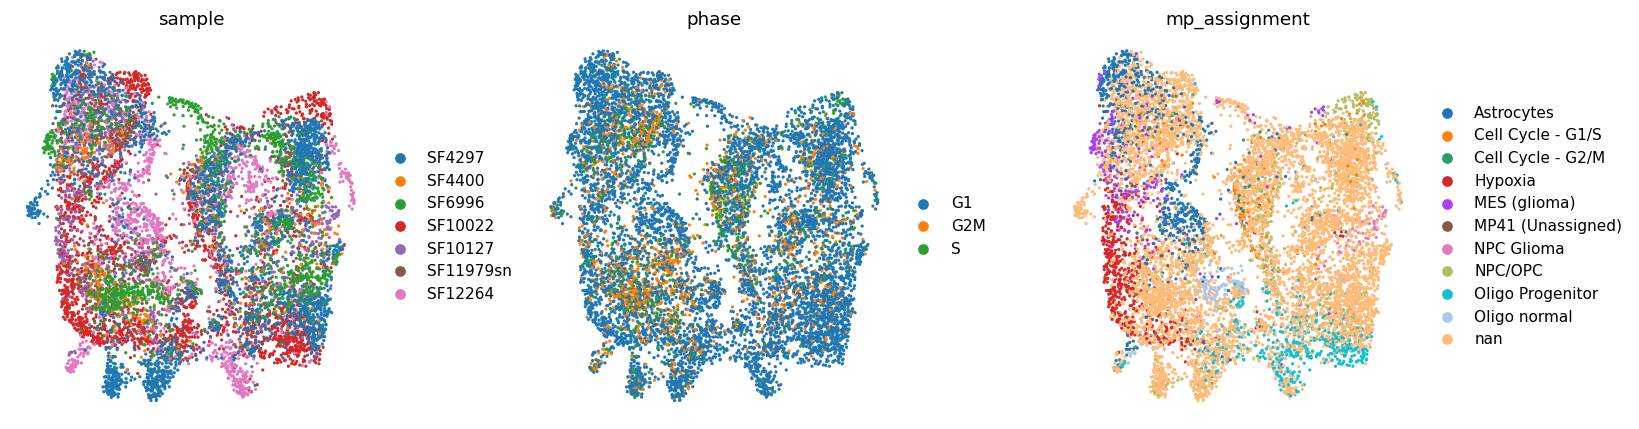

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['sample', 'phase', 'mp_assignment']):
    sc.pl.umap(adata, color=col, size=18, frameon=False, show=False, ax=ax, title=col)
fig.tight_layout(); plt.show()
n_samp = adata.obs['sample'].nunique()
print(f'GATE 1: {n_samp} samples intermixed on one continuous connected manifold (iLISI 2.60 of 7);')
print('        cell-cycle phase and metaprograms are scattered, no per-sample archipelago -> GO')

In [10]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (9634, 26409)


### Figure — samples.pdf (house (3.5,1.5) linear-trajectory aspect)

saved samples.pdf | cells: 9634


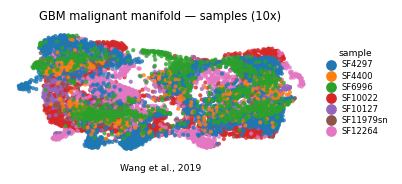

In [11]:
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('GBM malignant manifold — samples (10x)', size=7.5)
ax.text(.5, -.12, 'Wang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight'); plt.show()
print('saved samples.pdf | cells:', plot.shape[0])